# 04 · Research analysis: volatility, moneyness, maturity, payoff type

Experiments D–G.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from mc_greeks import *
from mc_greeks.estimators import exact_estimator_moments, per_path_function
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TABLES = ROOT / "results" / "tables"
pd.set_option("display.float_format", lambda v: f"{v:.6g}")

In [2]:
g = pd.read_csv(TABLES / 'G_equal_budget_summary.csv')
g[['payoff','greek','method','n','rmse','rmse_ratio_vs_malliavin','time_ratio_vs_malliavin','coverage']]

,payoff,greek,method,n,rmse,rmse_ratio_vs_malliavin,time_ratio_vs_malliavin,coverage
0,interval,delta,Malliavin,150000,9.84069e-06,1,1,0.98
1,interval,delta,FD-CRN-fwd,75000,0.000597366,60.7037,0.668713,0.88
2,interval,delta,FD-CRN-ctr,75000,0.000209826,21.3223,0.655488,0.96
3,interval,delta,FD-IND-fwd,75000,0.000976156,99.1959,0.875842,0.28
4,interval,delta,FD-IND-ctr,75000,0.000201951,20.522,0.874544,0.905
5,interval,gamma,Malliavin,150000,2.18828e-06,1,1,0.935
6,interval,gamma,FD-CRN-fwd,50000,0.000160674,73.4249,0.509572,0.735
7,interval,gamma,FD-CRN-ctr,50000,4.53714e-05,20.7338,0.509592,0.955
8,interval,gamma,FD-IND-fwd,50000,0.000217958,99.6027,0.818862,0.825
9,interval,gamma,FD-IND-ctr,50000,4.02862e-05,18.41,0.800802,0.945


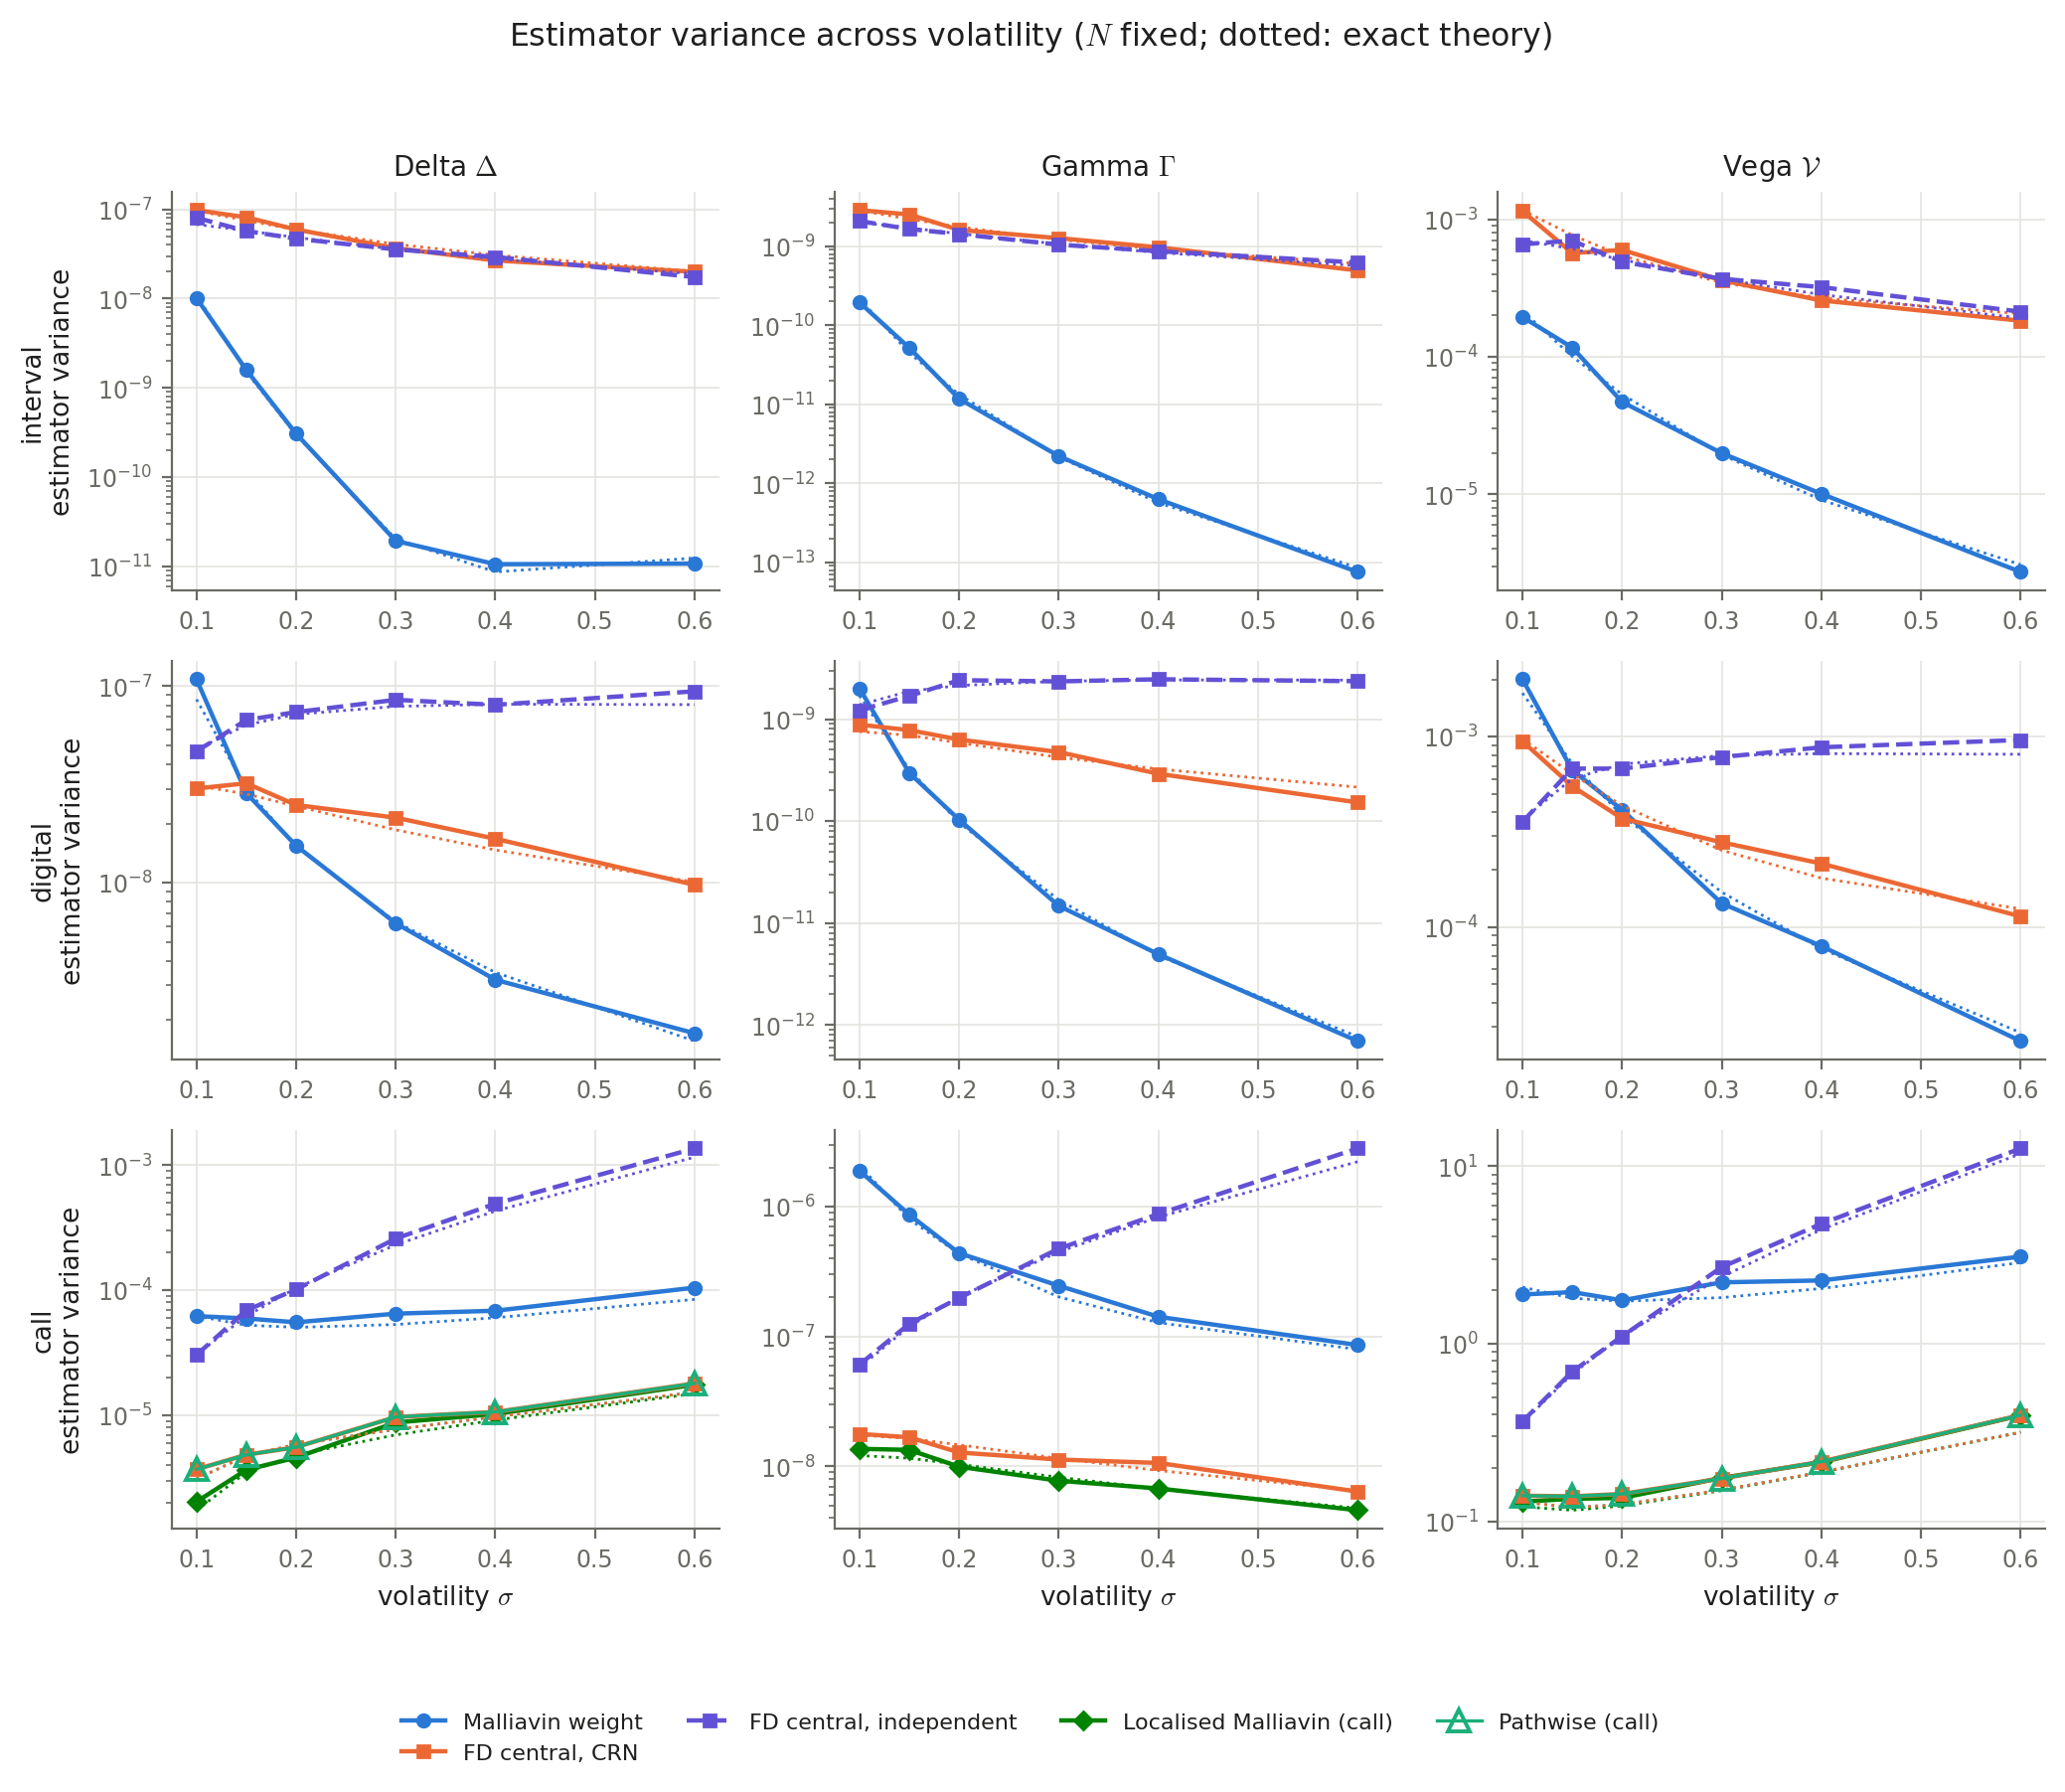

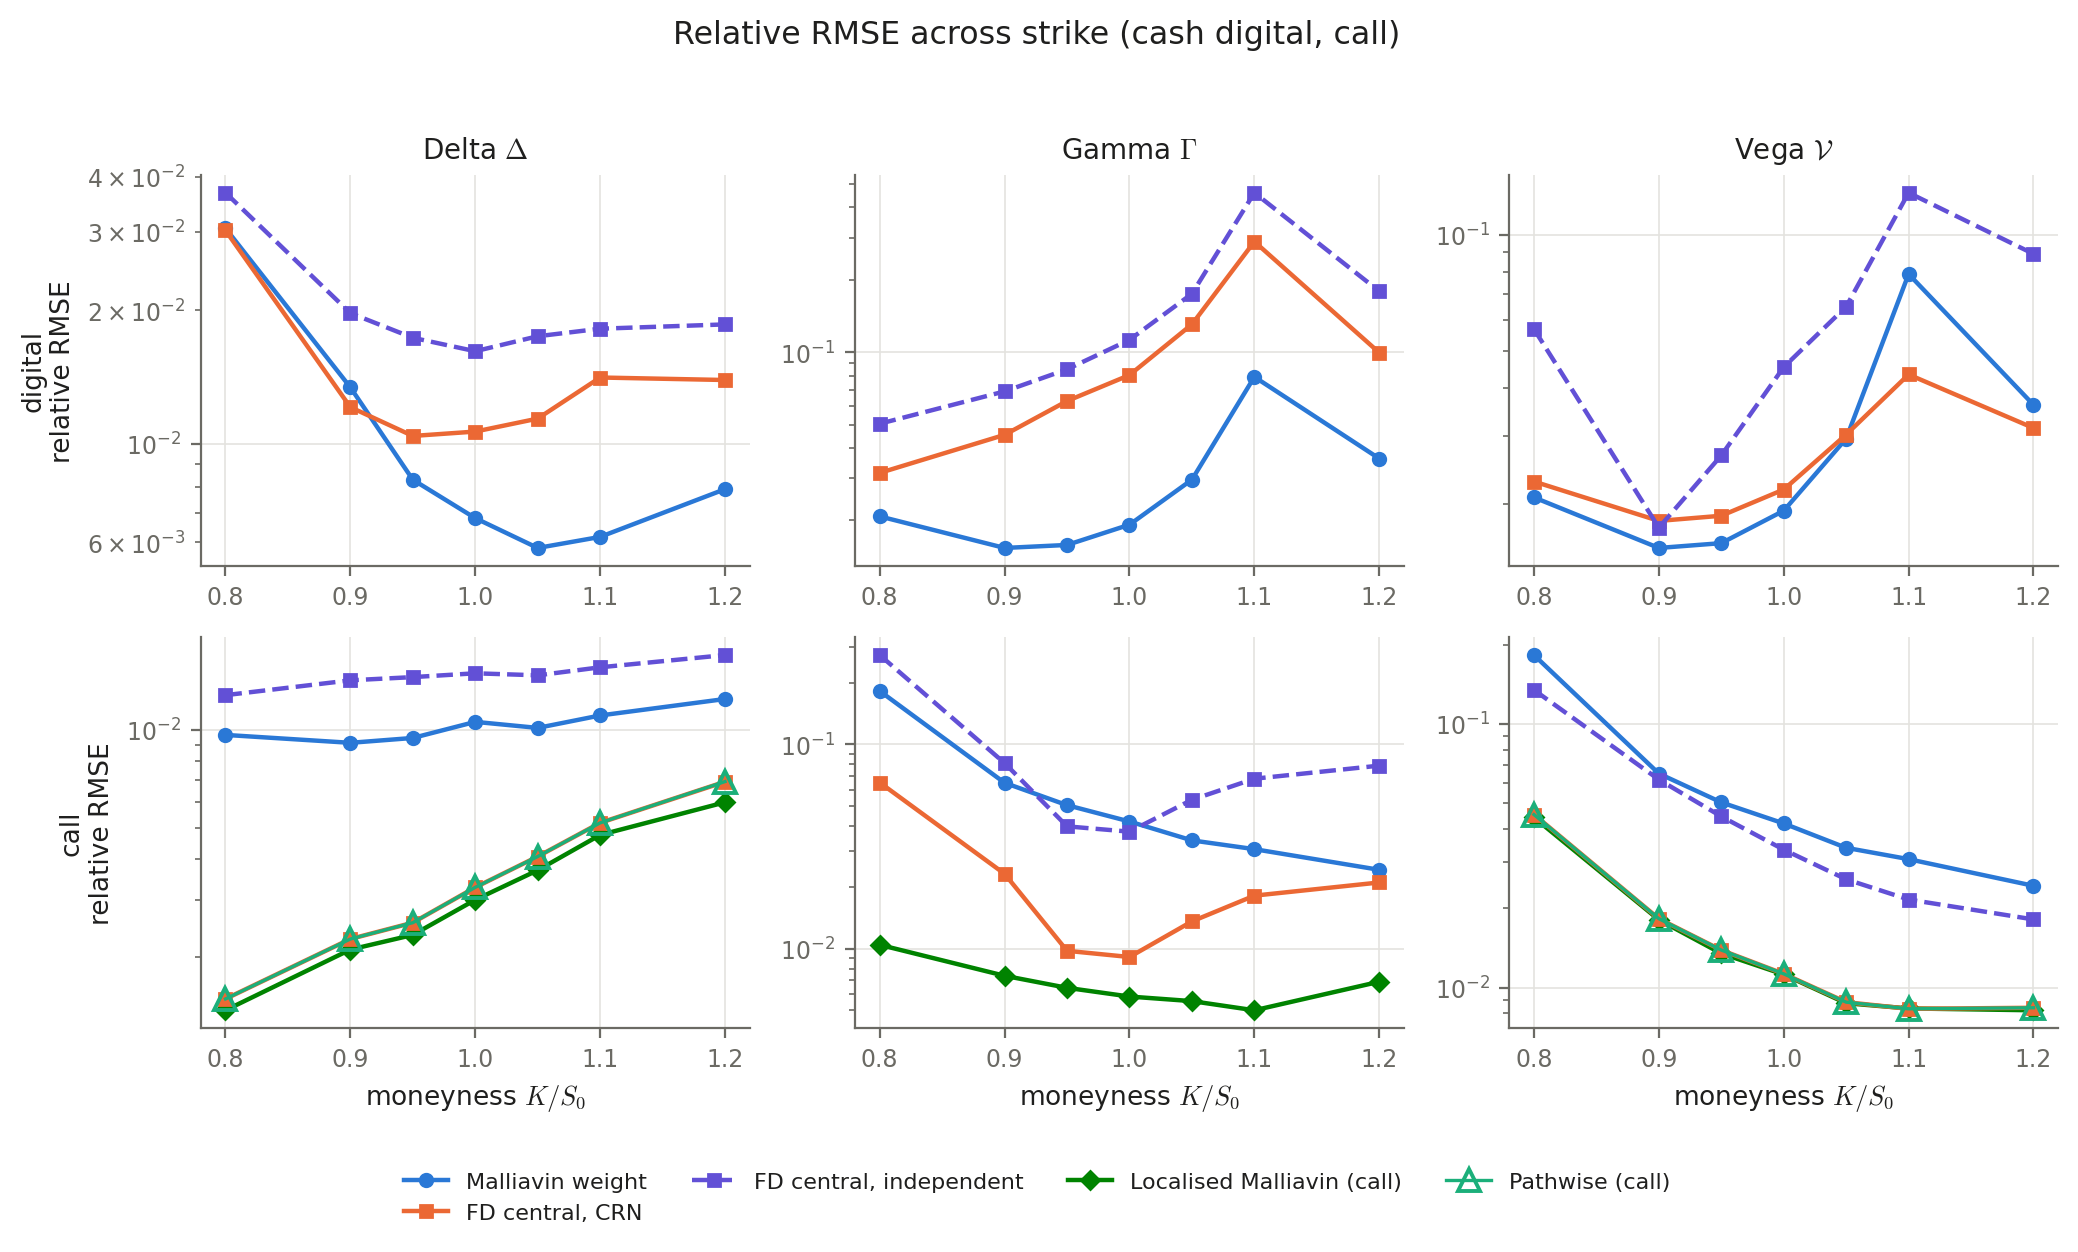

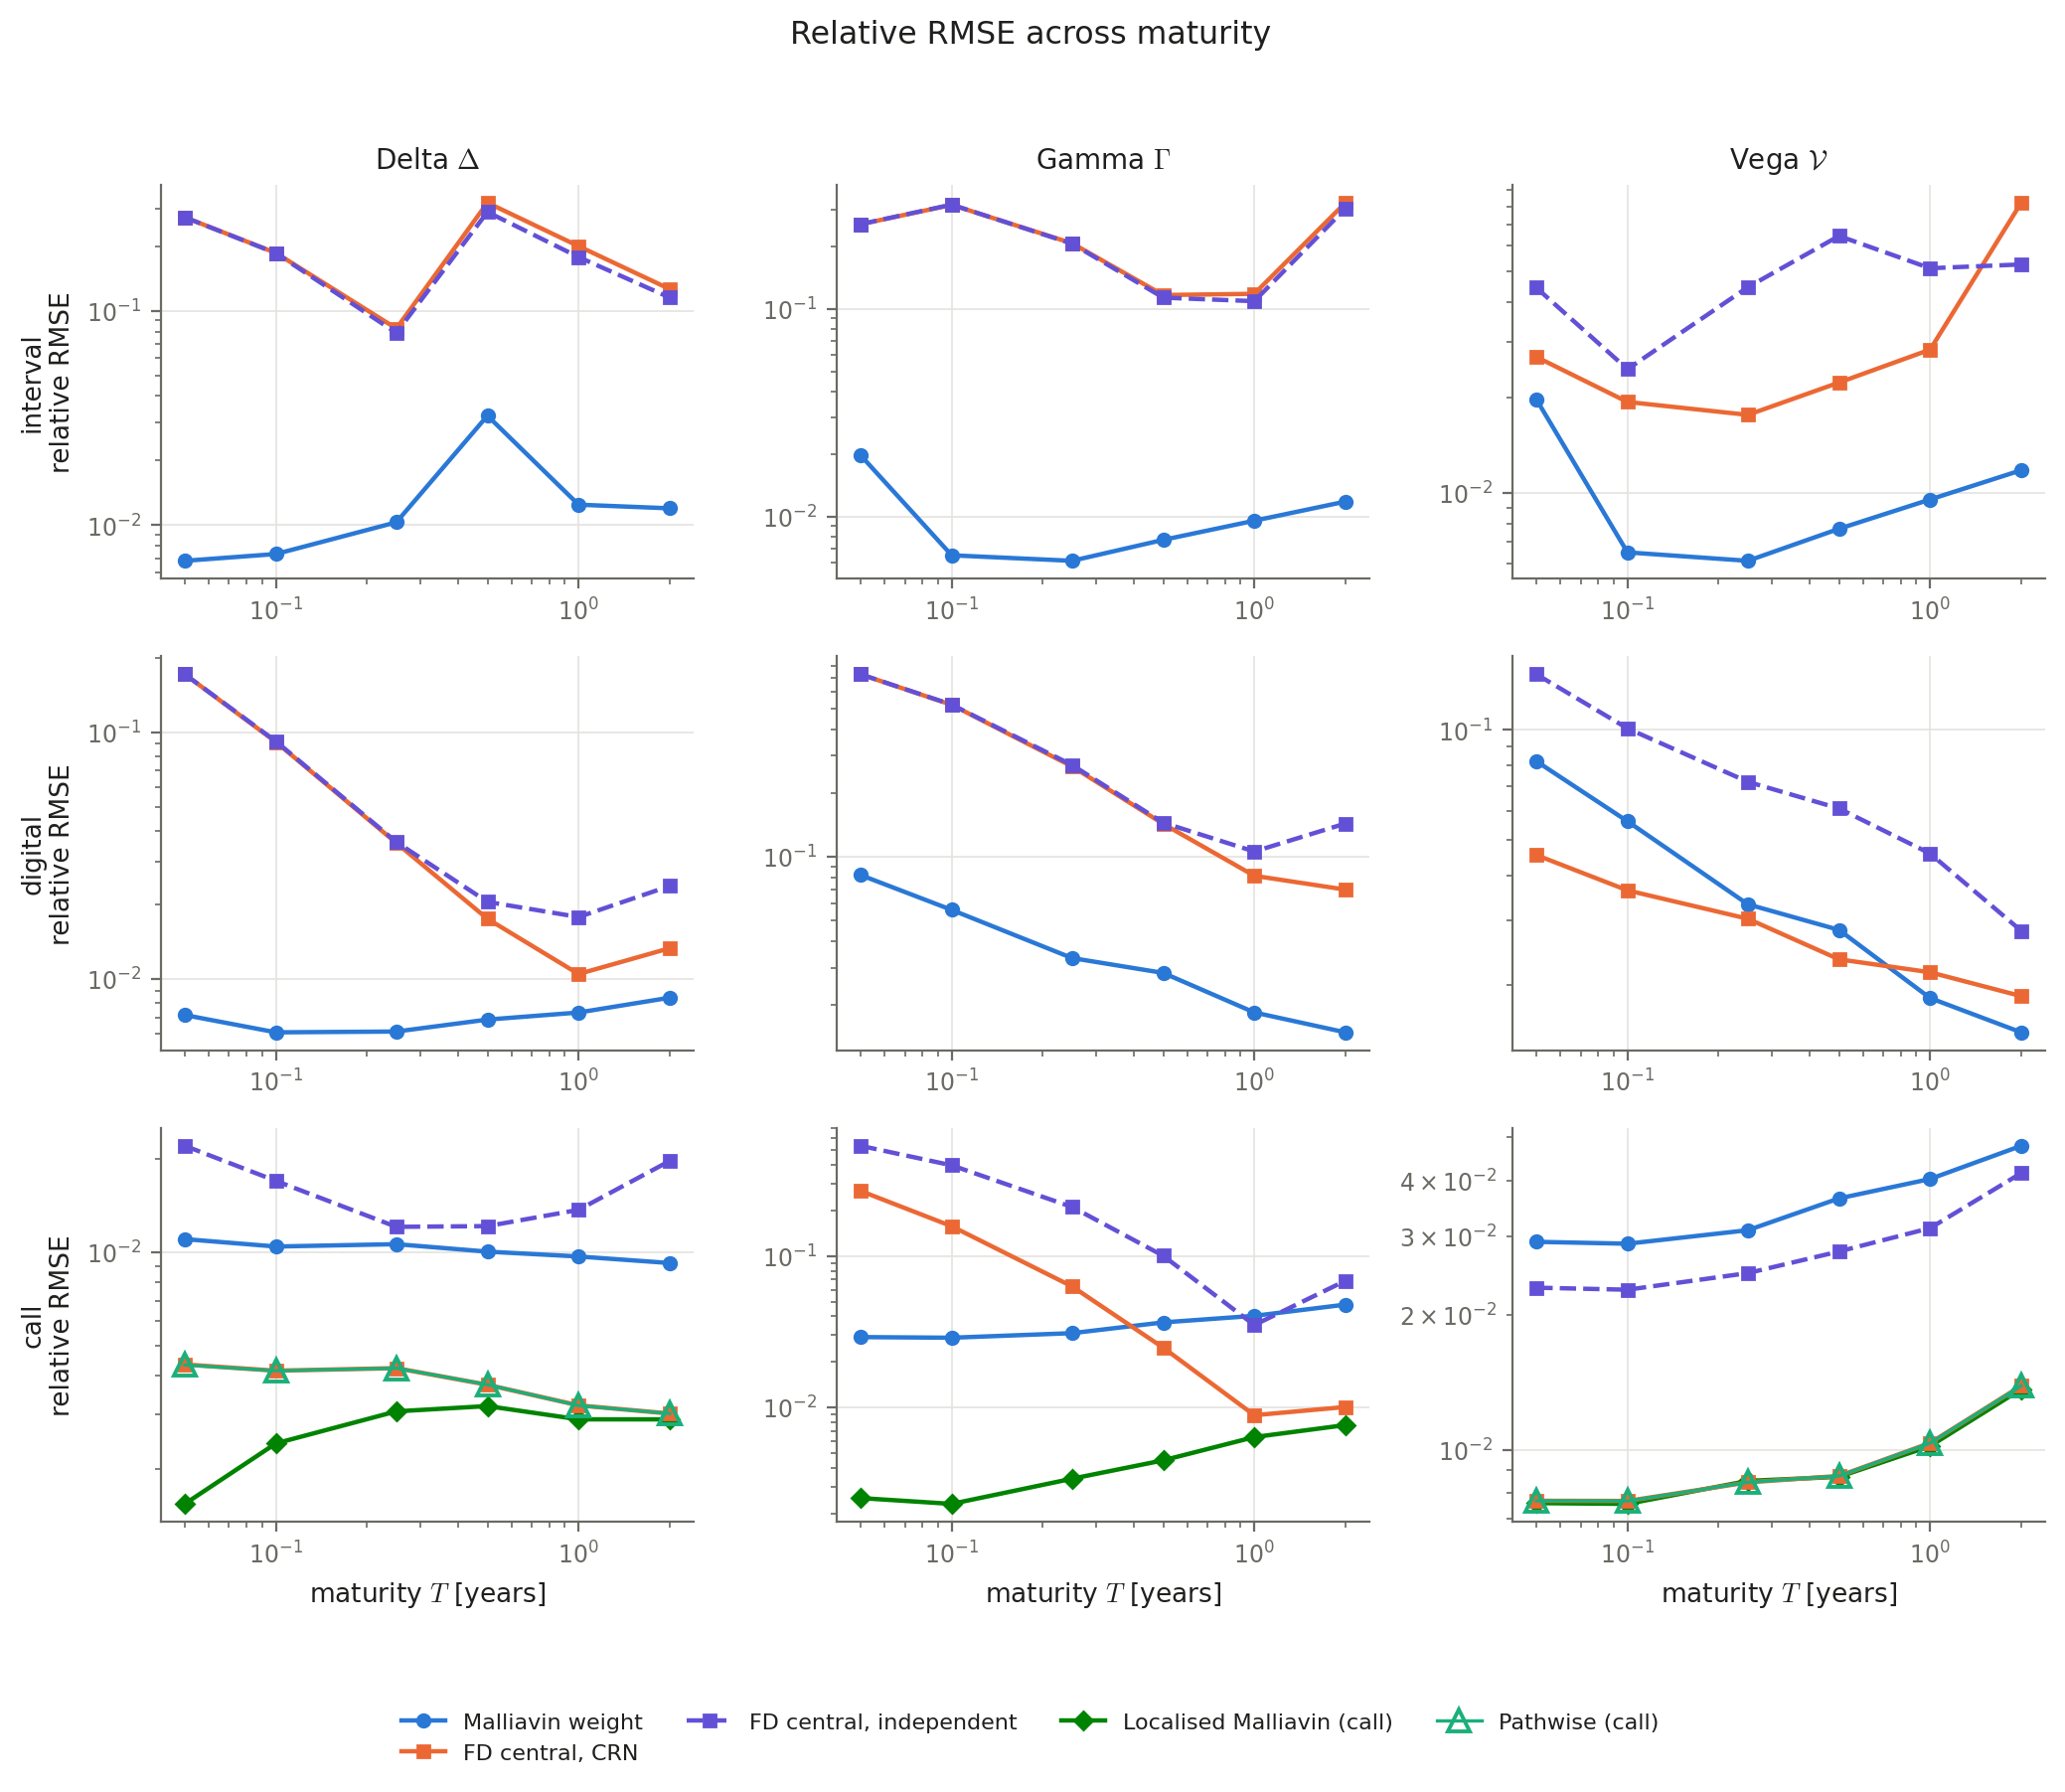

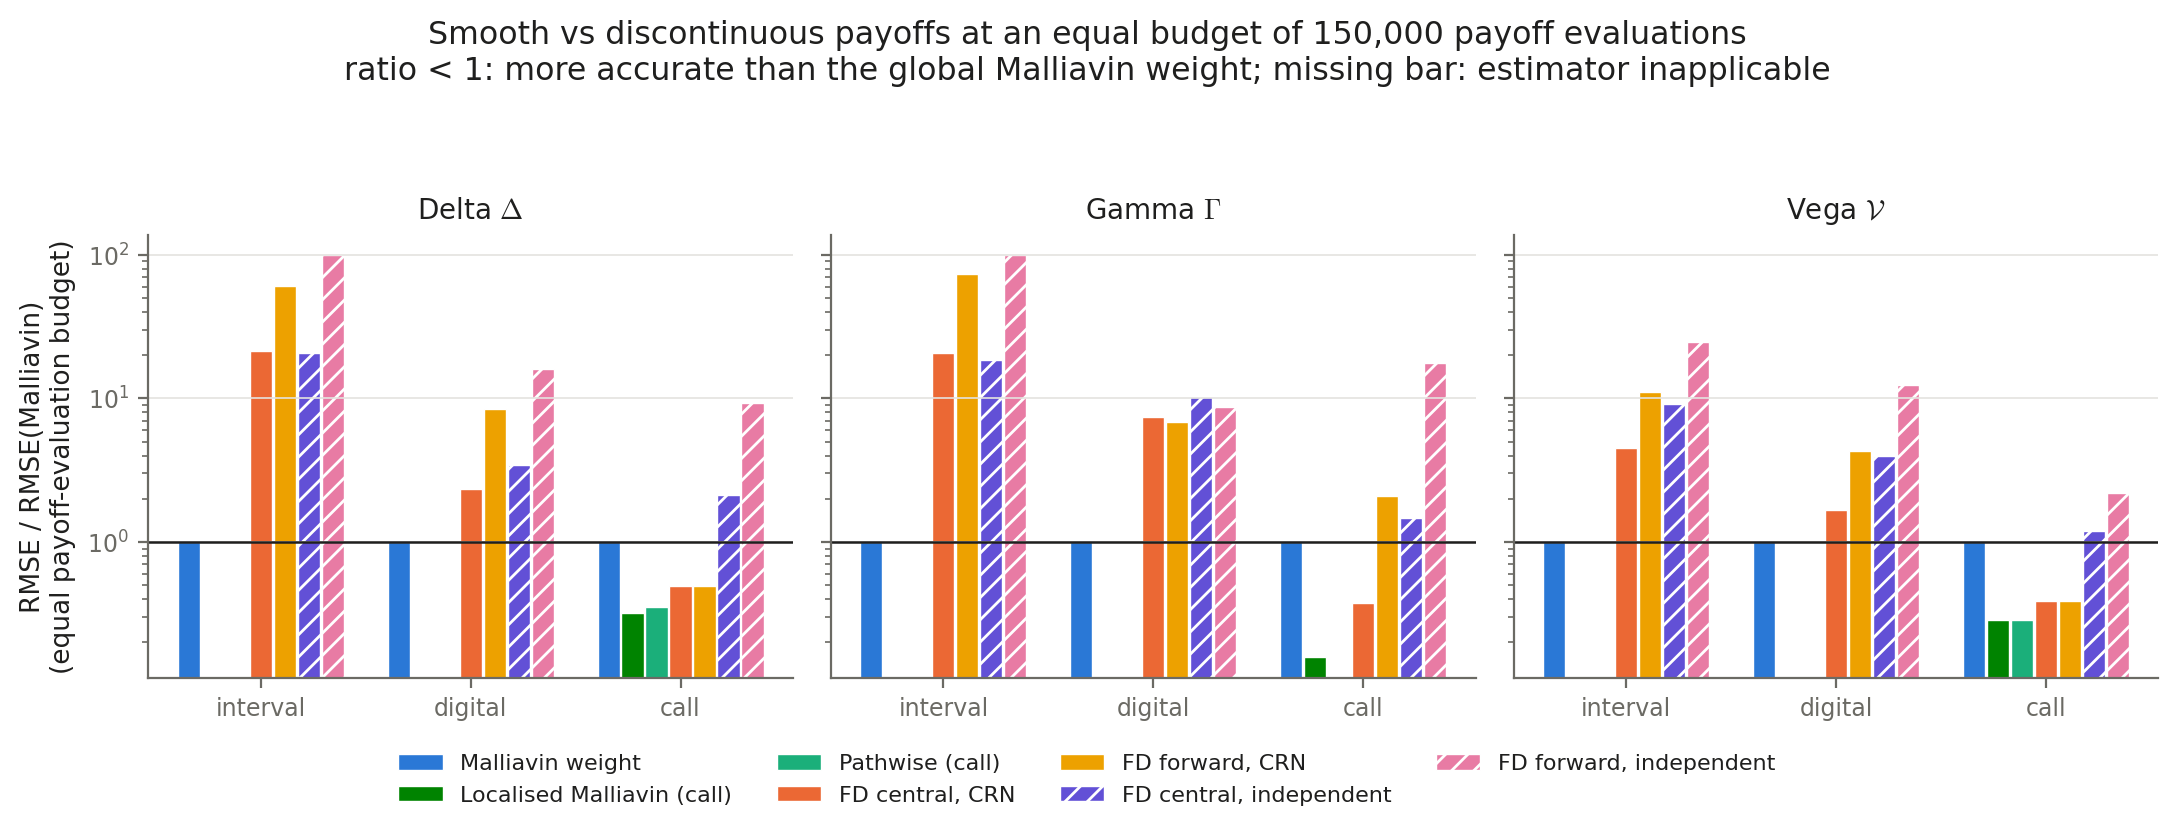

In [3]:
from IPython.display import Image, display
for f in ['fig07_variance_vs_volatility','fig08_rmse_vs_moneyness','fig09_rmse_vs_maturity','fig10_smooth_vs_discontinuous_equal_budget']:
    display(Image(str(ROOT / f'results/figures/{f}.png')))

Exact scaling of the Malliavin weight variance with σ and T (no simulation):

In [4]:
rows=[]
for T in [0.05, 0.25, 1.0]:
  for s in [0.1, 0.2, 0.4]:
    q = BlackScholesParams(100, 0.1, s, T)
    m = exact_estimator_moments('Malliavin', 'delta', CashDigitalCall(100), q)
    rows.append({'T':T,'sigma':s,'delta':m['truth'],'sd per path':m['var1']**0.5,'relative sd per path':m['var1']**0.5/abs(m['truth'])})
pd.DataFrame(rows)

,T,sigma,delta,sd per path,relative sd per path
0,0.05,0.1,0.173562,0.262926,1.51488
1,0.05,0.2,0.088407,0.130154,1.47222
2,0.05,0.4,0.0443779,0.0649494,1.46355
3,0.25,0.1,0.0695167,0.12124,1.74404
4,0.25,0.2,0.0381388,0.0575463,1.50887
5,0.25,0.4,0.0194485,0.0284745,1.46409
6,1,0.1,0.0229882,0.0654393,2.84665
7,1,0.2,0.0166612,0.027612,1.65726
8,1,0.4,0.00901317,0.0132146,1.46614


For the K = S0 digital the *relative* per-path standard deviation of the Malliavin Delta stays between about 1.5 and 2.9 over this grid, although the weight itself scales like 1/(σ√T): the true Delta grows at the same rate. (The equivalent ratio for Gamma varies much more, because the digital Gamma is proportional to d1 and passes through zero.)